In [ ]:
#| include: false
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
#| include: false
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle
from matplotlib.ticker import MultipleLocator
import numpy as np
from pathlib import Path
import cv2 as cv
from PIL import Image
from IPython.display import display

from miia_pec1.plot import plot_2D_transformations, plot_image, plot_arrow
import miia_pec1.transform_matrix as mtm


In [52]:
#| include: false

ROOT_DIR = Path.cwd()
DATA_DIR = ROOT_DIR / 'data'
ASSETS_DIR = ROOT_DIR / 'assets'

ASSETS_DIR.mkdir(exist_ok=True)

::: {.content-hidden .callout-note}
## Punto en 2D

Un punto en dos dimensiones se puede representar como:

$$
\mathbf{x} = \begin{bmatrix} x \\ y \end{bmatrix}
\qquad
\mathbf{x} = (x,y) \in \mathbb{R^2}
$$

Donde $\mathbb{R}^2$ representa el espacio de pares ordenados de números reales, $\mathbb{R}^2 = \{(x,y)\mid x,y\in\mathbb{R}\}$.

### Coordenadas homogéneas{.unnumbered}

Este punto puede representarse en un espacio de **coordenadas homogéneas**, como:

$$
\tilde{\mathbf{x}} = \begin{bmatrix} \tilde{x}\\ \tilde{y}\\ \tilde{w} \end{bmatrix},
\qquad
\tilde{\mathbf{x}} = (\tilde{x},\tilde{y},\tilde{w}) \in \mathbb{P^2}
$$

Siendo $\mathbb{P^2}$ el espacio proyectivo 2D.

En este espacio, dos vectores homogéneos no nulos que difieren únicamente por un factor de escala representan el mismo punto.

$$
(\tilde{x},\tilde{y},\tilde{w})
\sim
(\lambda\tilde{x},\lambda\tilde{y},\lambda\tilde{w}),
\qquad \lambda\neq 0
$$

Por ejemplo, los vectores $(2,4,1)$ y $(4,8,2)$ representan el mismo punto proyectivo.

### Conversión a coordenadas no homogéneas{.unnumbered}

Un vector $\tilde{\mathbf{x}}$ homogéneo puede volver a convertirse en *no homogeneo* $\mathbf{x}$ diviendolo por el último elemento $\tilde{w}$.

$$
\tilde{\mathbf{x}}
=
(\tilde{x},\tilde{y},\tilde{w})
=
\tilde{w}(x,y,1)
=
\tilde{w}\bar{\mathbf{x}}
$$

Donde $\bar{\mathbf{x}} = \begin{bmatrix} x\\ y\\ 1 \end{bmatrix}$ es el **vector aumentado**, una representación homogénea cuya última coordenada es igual a 1.

### Puntos ideales{.unnumbered}

Un punto homogéneo cuyo último elemento es $\tilde{w}=0$, no tiene un equivalente es el espacio de coordenadas reales, se conocen como **punto ideal** o **punto en el infinito**.
:::

:::{.content-hidden}
Partimos de la transformación básica, la traslación, para explicar el espacio de transformaciones geométricas.

$$
\mathbf{x}' = \mathbf{x} + \mathbf{t}
$$

$$
\mathbf{x}' =
\begin{bmatrix} 2 \\ 3 \end{bmatrix}
+
\begin{bmatrix} 4 \\ 2 \end{bmatrix}
=
\begin{bmatrix} 6  \\ 5 \end{bmatrix}
$$
:::

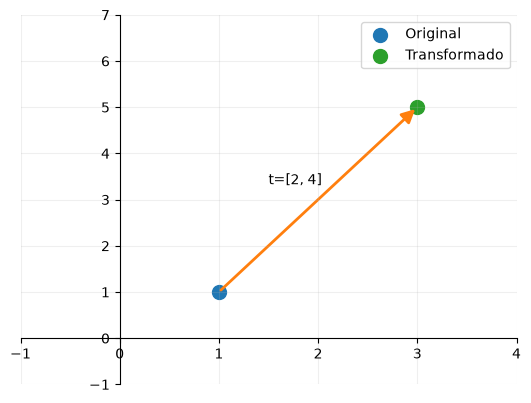

In [53]:
# | include: false
x = np.array([1, 1])
t = np.array([2, 4])

x_t = x + t

ax = plot_2D_transformations(x, x_t, x_lim=(-1, 4), y_lim=(-1, 7))

plot_arrow(ax, x, x_t, color='tab:orange')
ax.text(x_t[0] / 2, x_t[1] / 1.5, f"t=[{t[0]}, {t[1]}]")

plt.show()


::: {.content-hidden}
Se puede representar la misma operación de forma matricial como:

$$
\mathbf{x}' = \begin{bmatrix} \mathbf{I} & \mathbf{t} \end{bmatrix} \bar{\mathbf{x}}
$$

Donde $\mathbf{I}$ es la matriz identidad:

$$
\mathbf{I} = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}
$$

Y $\bar{\mathbf{x}}$ es el **vector de aumento**, que nos permite aplicar la traslación como una operación matricial:

$$
\bar{\mathbf{x}} = \begin{bmatrix} 2 \\ 3 \\ 1 \end{bmatrix}
$$

La operación pasa a ser:

$$
\mathbf{x}' = 
\begin{bmatrix} 
1 & 0 & 4\\ 
0 & 1 & 2
\end{bmatrix}
\begin{bmatrix} 2 \\ 3 \\ 1 \end{bmatrix}
=
\begin{bmatrix} 6 \\ 5 \end{bmatrix}
$$

Usar una matriz $2x3$ resulta en una notación más compacta, pero agregando la fila $\begin{bmatrix} \mathbf 0^T & 1 \end{bmatrix}$, la convertimos en una matriz $3x3$, esto hace posible encadenar transformaciones mediante mutiplicaciones y aplicar la transformación inversa.

$$
\bar{\mathbf{x}}'= \begin{bmatrix} \mathbf{I} &\mathbf{t} \\ \mathbf 0^T & 1 \end{bmatrix} \bar{\mathbf{x}}
$$

Añadir $\begin{bmatrix} 0 0 1 \end{bmatrix}$ como última fila, garantiza que el coordenada adicional del siga siendo 1.

$$
\bar{\mathbf{x}}'= 
\begin{bmatrix}
1 & 0 & 4 \\
0 & 1 & 2 \\
0 & 0 & 1
\end{bmatrix}
\begin{bmatrix}
2 \\ 3 \\ 1
\end{bmatrix}
=
\begin{bmatrix}
6 \\ 5 \\ 1
\end{bmatrix}
$$
:::

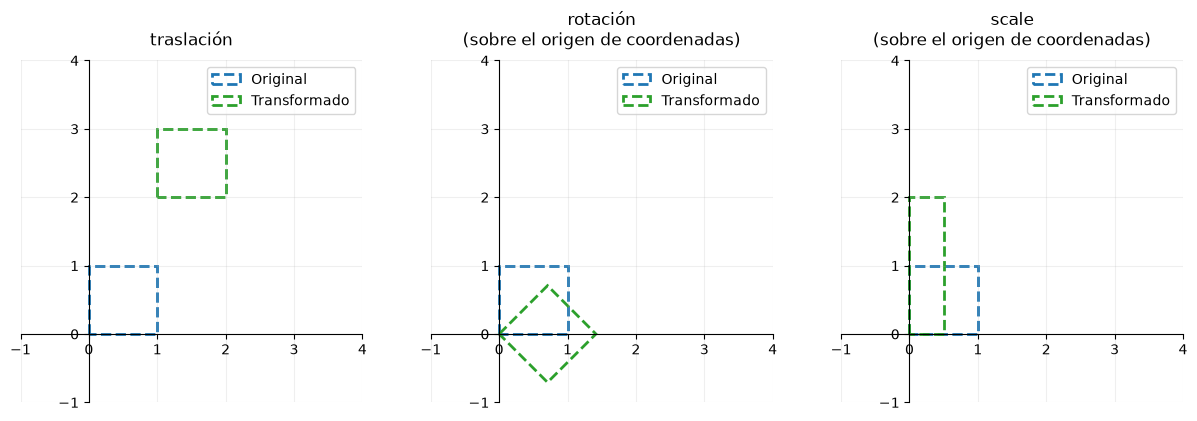

In [54]:
# | include: false
transformations = {
    "traslación": mtm.TRANSLATE(t_x=1, t_y=2),
    "rotación\n(sobre el origen de coordenadas)": mtm.ROTATE(45),
    "scale\n(sobre el origen de coordenadas)": mtm.SCALE(f_x=0.5, f_y=2),
}

X = np.array([[0, 0], [0, 1], [1, 1], [1, 0], [0, 0]])
X_augmeted = np.hstack((X, np.ones((X.shape[0], 1))))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for (transform, T), ax in zip(transformations.items(), axes):
    X_t = (T @ X_augmeted.T).T
    ax = plot_2D_transformations(
        X, X_t[:, :2], ax=ax, x_lim=(-1, 4), y_lim=(-1, 4), title=transform
    )

    ax.set_aspect("equal")

plt.show()


## Ejercicio 2.1


Se puede rotar una imagen respecto al centro de la imagen, aplicando una transformación afín utilizando la función `cv2.getRotationMatrix2D()`  [@opencv2026geometric].

La matriz de rotación de OpenCV [@opencv2026geometric] incorpora el centro de rotación y un factor de escala.

$$
M = \begin{bmatrix}
\alpha & \beta & (1-\alpha)c_x-\beta c_y\\
-\beta & \alpha & \beta c_x+(1-\alpha)c_y
\end{bmatrix}
$$

donde

$$
\begin{aligned}
\alpha &= s\cos\theta\\
\beta &= s\sin\theta
\end{aligned}
$$

Como se puede ver en @lst-rotation-matrix esta matriz es equivalente a realizar las siguientes transformaciones de forma encadenada:

```{mermaid}
%%| fig-width: 6
%%| label: fig-rotacion
%%| fig-cap: "Rotar una imagen respecto a su centro"
flowchart LR
    T1["Trasladar el centro de la imagen al origen de coordenadas"]
    R["Rotar la imagen"]
    T2["Trasladar la imagen de vuelta a su posición original"]
    
     T1 --> R
     R --> T2

```

In [55]:
#| lst-label: lst-rotation-matrix
#| lst-cap: "Composición de transformaciones afines"
# Escogemos el centro de rotación
c_h, c_w = 100, 200

# Matriz de rotación con OpenCV
rot = cv.getRotationMatrix2D((c_w, c_h), 30, 1)

# Rotación respecto (c_w, c_h) con transformaciones afines

# Trasladar el centro de la imagen al origen de coordenadas
T1 = mtm.TRANSLATE(t_x=-c_w, t_y=-c_h)
# Rotar la imagen respecto al origen de coordeandas
R = mtm.ROTATE(30)
# Trasladar la imagen de vuelta al su posición original
T2 = mtm.TRANSLATE(t_x=c_w, t_y=c_h)

# Matriz de rotación calculada
M = T2 @ R @ T1

print(f'np.allclose(M[:2,:], rot) = {np.allclose(M[:2,:], rot)}')

np.allclose(M[:2,:], rot) = True


Al rotar una imagen las dimensiones del marco de salida cambian, si no ajustamos las dimensiones al nuevo marco perdemos información de la imagen original.

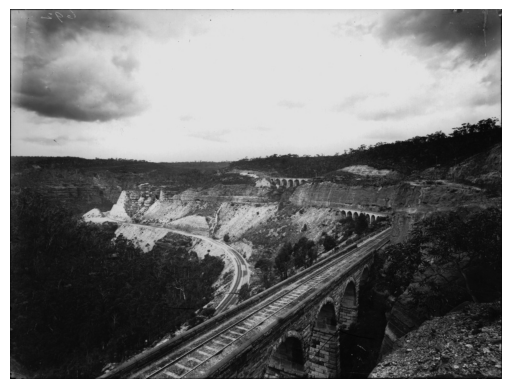

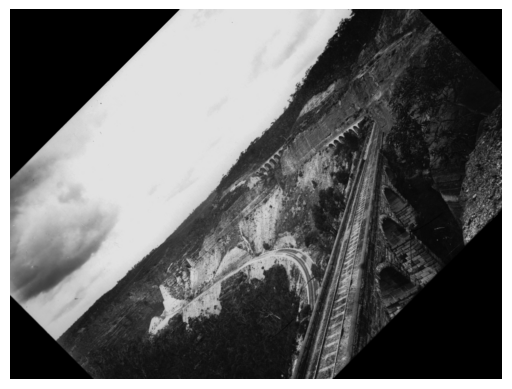

In [56]:
#| echo: false
#| label: fig-rotate-image
#| fig-cap: "Rotación"
#| fig-subcap:
#|  - "Imagen original"
#|  - "Imagen rotada 45º en el frame orginal"
#| layout-ncol: 2
img = cv.imread(DATA_DIR / "zigzag.jpg", cv.IMREAD_COLOR_RGB)

h, w = img.shape[:2]
c_h, c_w = h//2, w//2

R = cv.getRotationMatrix2D((c_w, c_h), 45, scale=1)
img_scaled = cv.warpAffine(img, R, dsize=(w, h))

plot_image(img)
plot_image(img_scaled)

plt.show()

Para evitar la pérdida de información durante la rotación de una imagen, es necesario ajustar las dimensiones del marco de salida de modo que contenga completamente la imagen transformada [@rosebrock2017rotate].

Las nuevas dimensiones pueden calcularse a partir de las proyecciones horizontales y verticales de los lados de la imagen original, como se ilustra en @fig-proyect-dimensions.

Una vez calculadas estas dimensiones, es necesario situar el centro de la imagen original en el centro del nuevo marco, evitando así que la imagen rotada quede recortada.

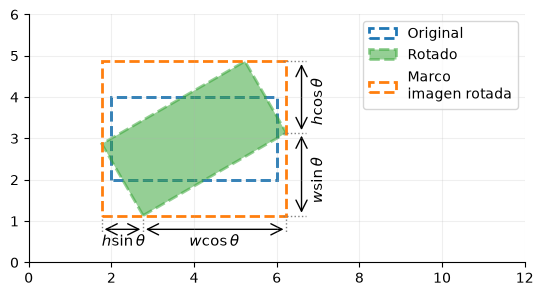

In [57]:
#| echo: false
#| label: fig-proyect-dimensions
#| fig-cap: "Dimensiones proyectadas"
fig, ax = plt.subplots(1,1)

# Fakeo de un rectangulo
x = np.array([
    [2, 2],
    [2, 4],
    [6, 4],
    [6, 2],
    [2, 2]
])
h, w = 2, 4
c_h, c_w = 3, 4
x = np.hstack((x, np.ones((x.shape[0], 1))))

# Cálculo de matriz de transformación para rotar desde su centro
T1 = mtm.TRANSLATE(-4, -3)
R = mtm.ROTATE(-30)
T2 = mtm.TRANSLATE(4, 3)
M = T2 @ R @ T1

x_t = (M @ x.T).T

# Mínimo y máximo de rectangulo rotado, para pintar el marco que lo contiene
x_t_min, y_t_min, _ = x_t.min(axis=0)
x_t_max, y_t_max, _ = x_t.max(axis=0)
h_t, w_t = y_t_max - y_t_min, x_t_max - x_t_min

# Dimensiones proyectdas del recatángulo
cos = np.abs(R[0, 0])
sen = np.abs(R[1, 0])

w_cos = w * cos
w_sen = w * sen
h_cos = h * cos
h_sen = h * sen

ax.add_patch(Polygon(x[:, :2], closed=True, fill=False, lw=2, ls='--', color='tab:blue', label='Original'))
ax.add_patch(Polygon(x_t[:, :2], closed=True, fill=True, alpha=.5, lw=2, ls='--', color='tab:green', label='Rotado'))
ax.add_patch(Rectangle((x_t_min, y_t_min), w_t, h_t, fill=False, lw=2, ls='--', color='tab:orange', label='Marco\nimagen rotada'))

# w': ancho proyectado
plot_arrow(ax, (x_t_min, .8), (x_t_min + h_sen, .8), lw=1, style='<->')
plot_arrow(ax, (x_t_min + h_sen, .8), (x_t_max, .8), lw=1, style='<->')
ax.text(
    2.3, .5, r'$h\sin{\theta}$',
    fontsize=11,
    ha="center", va="center"
)
ax.text(
    4.5, .5, r'$w\cos{\theta}$',
    fontsize=11,
    ha="center", va="center"
)
for x in [x_t_min, x_t_min + h_sen, x_t_max]:
    ax.plot(
        [x, x], [y_t_min-0.08, .7],
        color="gray", ls=":", lw=1
    )

# h': alto proyectado
plot_arrow(ax, (6.6, y_t_max), (6.6, y_t_max - h_cos), lw=1, style='<->')
plot_arrow(ax, (6.6, y_t_max - h_cos), (6.6, y_t_min), lw=1, style='<->')
ax.text(
    7, 3.9, r'$h\cos{\theta}$',
    fontsize=11, rotation=90,
    ha="center", va="center"
)
ax.text(
    7, 2, r'$w\sin{\theta}$',
    fontsize=11, rotation=90,
    ha="center", va="center"
)
for y in [y_t_max, y_t_max - h_cos, y_t_min]:
    ax.plot(
        [x_t_max-0.08, 6.7], [y, y],
        color="gray", ls=":", lw=1
    )

ax.set_xlim(0, 12)
ax.set_ylim(0, 6)

ax.grid(alpha=0.2)
ax.legend(loc='upper right')
ax.set_aspect("equal")

ax.spines[['top', 'right']].set_visible(False)

plt.show()

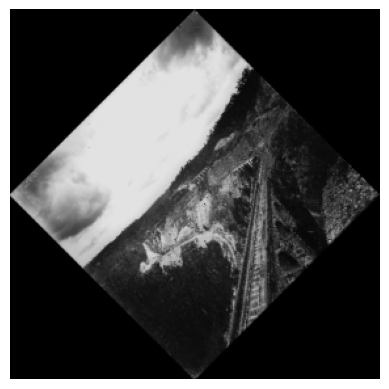

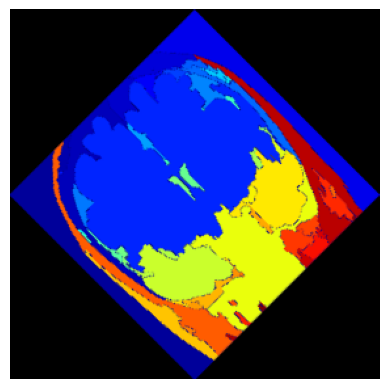

In [58]:
#| echo: false
#| label: fig-exercise-2-1
#| fig-cap: "Escalado y rotación de imágenes con ajuste del marco de salida"
#| fig-subcap:
#|   - "Imagen zigzag"
#|   - "Imagen brainLabels"
#| layout-ncol: 2
#| layout-valign: center

img_zigzag = cv.imread(DATA_DIR / "zigzag.jpg", cv.IMREAD_COLOR_RGB)
img_brain = cv.imread(DATA_DIR / "brainLabels.png", cv.IMREAD_COLOR_RGB)

# Resize
SCALE_SIZE=(200, 200)
ROTATION_ANGLE=-45
img_zigzag_resize = cv.resize(img_zigzag, dsize=SCALE_SIZE)
img_brain_resize = cv.resize(img_brain, dsize=SCALE_SIZE)

# Rotación, la función `mtm.rotate_bound` utiliza la implementación de `@rosebrock2017rotate` que establece
# el giro en sentido horario, para rotar 45 en sentido antihorario se especifica -45
img_zigzag_resize_rot = mtm.rotate_bound(img_zigzag_resize, ROTATION_ANGLE)
img_brain_resize_rot = mtm.rotate_bound(img_brain_resize, ROTATION_ANGLE)


plot_image(img_zigzag_resize_rot)
plot_image(img_brain_resize_rot)

plt.show()

## Ejercicio 2.2

### Implementación de las transformaciones de forma individual

```{mermaid}
%%| fig-width: 6
---
title: Rotar una imagen respecto a su centro
---
flowchart LR
    T1["Reescalar 1/4 ambos ejes"]
    T2["Shear -30ª sobre el eje X"]
    T3["Giro 90º (sentido antihorario)"]
    
     T1 --> T2
     T2 --> T3

```

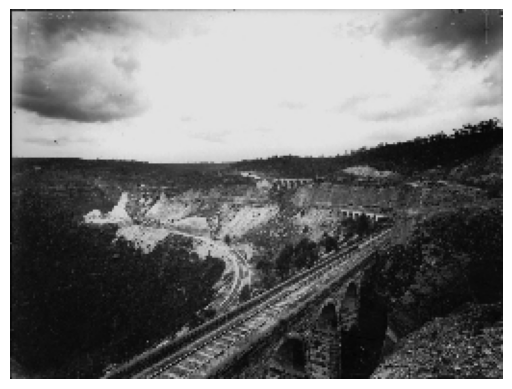

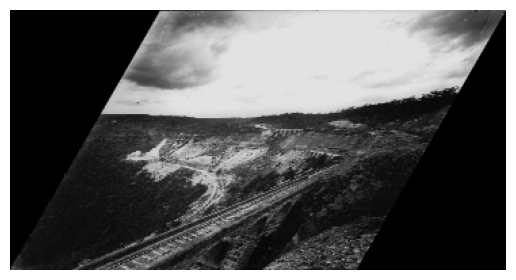

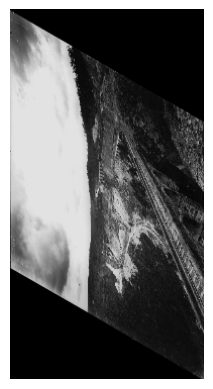

In [59]:
#| echo: false
#| label: fig-exercise-2-2-1-1
#| fig-cap: "Composición de transformaciones afines sobre una imagen"
#| fig-subcap:
#|  - "Escalado uniforme (1/4)"
#|  - "Shear horizontal (-30º)"
#|  - "Rotación antihoraria (90ª)"
#| layout-ncol: 3
#| layout-valign: center

# Definición de las transformaciones
SCALE_FACTOR=1/4
SHEAR_ANGLE=30
ROTATION_ANGLE=90

transformations = {
    'resize': mtm.SCALE(f_x=SCALE_FACTOR, f_y=SCALE_FACTOR),
    'shearx': mtm.SHEAR_X(-30),
    'rotate': mtm.ROTATE(ROTATION_ANGLE),
}


img = cv.imread(DATA_DIR / 'zigzag.jpg', cv.IMREAD_COLOR_RGB)
h, w = img.shape[:2]

# T1
T1 = transformations['resize']
h_scale, w_scale = int(h*SCALE_FACTOR), int(w*SCALE_FACTOR)
img_scale = cv.warpAffine(img, T1[:2, :], dsize=(w_scale, h_scale))
plot_image(img_scale)


# T2
# Para no perder información se divide la operación:
#   1. ShearX de la imagen
#   2. Cálculo del nuevo marco
#   3. Traslación para centrar la imagen
A = transformations['shearx']
tan = np.abs(A[0, 1])
h_shear, w_shear = h_scale, int(tan*h_scale) + w_scale

B = mtm.TRANSLATE(t_x=int(tan*h_scale), t_y=0)
T2 = A @ B

img_shear = cv.warpAffine(img_scale, T2[:2,:], dsize=(w_shear, h_shear))
plot_image(img_shear)


# T3
# Para rotar la imagen 90º
#   1. Trasladar el centro de la imagen al centro de coordenadas
#   2. Rotar la imagen
#   3. Calcular el nuevo marco de la imagen
#   4. Mover el centro de la imagen al centro del nuevo marco
c_h, c_w = h_shear//2, w_shear//2
h_rotate, w_rotate = w_shear, h_shear
c_h_rotate, c_w_rotate= h_rotate//2, w_rotate//2

A = mtm.TRANSLATE(t_x=-c_w, t_y=-c_h)
B = mtm.ROTATE(90)
C = mtm.TRANSLATE(t_x=c_w_rotate, t_y=c_h_rotate)

T3 = C @ B @ A

img_rotate = cv.warpAffine(img_shear, T3[:2,:], dsize=(w_rotate, h_rotate))
plot_image(img_rotate)

plt.show()

### Implementación de las transformaciones compuestas

En la composición de transformaciones geométricas, el orden de las transformaciones afecta al resultado, ya que la multiplicación de matrices no es conmutativa [@wikipediaMatrix]:

$$
\mathbf{A}\mathbf{B}\neq\mathbf{B}\mathbf{A}
$$

Por ejemplo, dadas las matrices:

$$
\mathbf{A} =
\begin{bmatrix}
1 & 2\\
3 & 4
\end{bmatrix},
\qquad
\mathbf{B} =
\begin{bmatrix}
0 & 1\\
0 & 0
\end{bmatrix}
$$

Se obtienen los siguientes productos:

$$
\mathbf{A}\mathbf{B} =
\begin{bmatrix}
0 & 1\\
0 & 3
\end{bmatrix},
\qquad
\mathbf{B}\mathbf{A} =
\begin{bmatrix}
3 & 4\\
0 & 0
\end{bmatrix}
$$

Sin embargo, la multiplicación de matrices sí cumple la propiedad asociativa, que permite agrupar varias transformaciones en una única matriz sin alterar el resultado.

Para un punto representado mediante el vector columna $\mathbf{x}$, si primero se aplica la transformación $\mathbf{T}_1$ y posteriormente $\mathbf{T}_2$, se obtiene:

$$
\mathbf{x}' = \mathbf{T}_2(\mathbf{T}_1\mathbf{x}) = (\mathbf{T}_2\mathbf{T}_1)\mathbf{x} = \mathbf{T}_C\mathbf{x}
$$

donde $\mathbf{T}_C=\mathbf{T}_2\mathbf{T}_1$ representa la matriz de transformación compuesta.

Como se muestra en @fig-matrix-composition, el orden de aplicación de las transformaciones afecta al resultado final. En el primer caso se aplica una traslación seguida de una rotación, mientras que en el segundo se invierte el orden, obteniéndose posiciones finales diferentes para un mismo punto inicial.

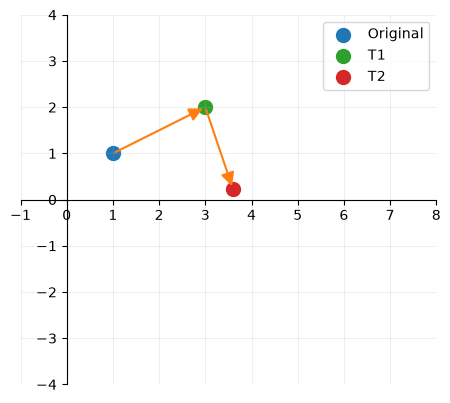

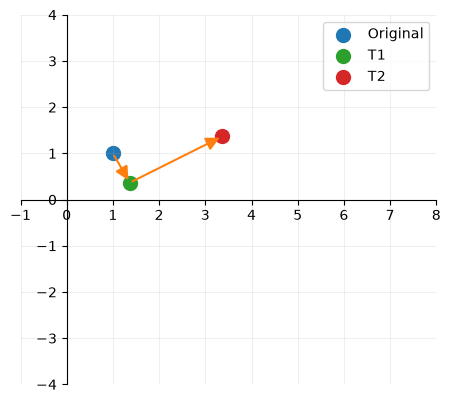

In [60]:
#| echo: false
#| label: fig-matrix-composition
#| fig-cap: "Efecto del orden de aplicación de las transformaciones geométricas"
#| fig-subcap:
#|  - "Traslación seguida de rotación"
#|  - "Rotación seguida de traslación"
#| layout-ncol: 2
#| layout-valign: center

# Punto en el espacio homogeneo
x_point = np.array([[1], [1], [1]])
A = mtm.TRANSLATE(t_x=2, t_y=1)
B = mtm.ROTATE(30)

for M1, M2 in ((A, B), (B, A)):
    x_t1 = M1 @ x_point
    x_t2 = M2 @ x_t1

    fig, ax = plt.subplots(1, 1)

    points = [
        [x_point[:2].flatten(), 'tab:blue', 'Original'],
        [x_t1[:2].flatten(), 'tab:green', 'T1'],
        [x_t2[:2].flatten(), 'tab:red', 'T2'],
    ]

    for point, color, label in points:
        ax.scatter(
            *point,
            marker='o',
            s=100,
            color=color,
            label=label
        )

    plot_arrow(ax, points[0][0], points[1][0], lw=1.5, color='tab:orange')
    plot_arrow(ax, points[1][0], points[2][0], lw=1.5, color='tab:orange')

    ax.grid(alpha=0.2)
    ax.legend(loc='upper right')

    ax.set_xlim((-1, 8))
    ax.set_ylim((-4, 4))

    ax.spines[['top', 'right']].set_visible(False)
    ax.spines['bottom'].set_position(('data', 0))
    ax.spines['left'].set_position(('data', 0))

    ax.set_aspect("equal")

plt.show()

El resultado de realizar las transformaciones mediante composición de matrices, se muestra en la @fig-exercise-2-2-1-2-1, geométricamente el resultado es el mismo. Sin embargo, si observamos el detalle de las intensidades de los píxeles resultantes, en la figura @fig-exercise-2-2-1-2-2, no son iguales. Cada transformación sobre la imagen realiza una interpolación, en las transformaciones individuales por tanto se están aplicando tres interpolaciones, por una en el caso de la transformación compuesta.

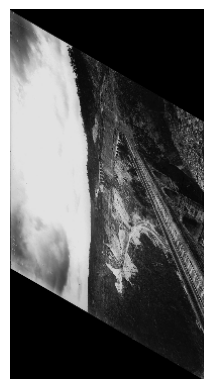

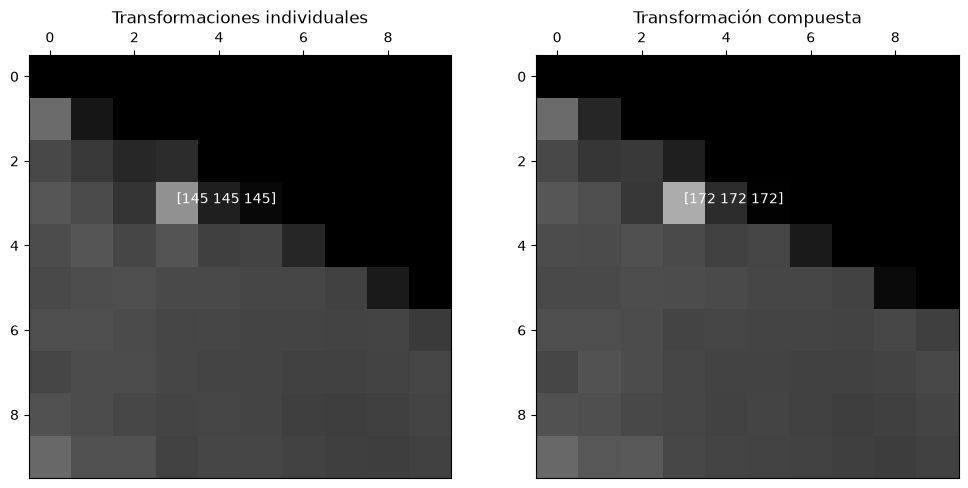

In [61]:
#| echo: false
#| label: fig-exercise-2-2-1-2
#| fig-cap: "Aplicación de transformaciones afines mediante composición de matrices"
#| fig-subcap:
#|  - "Resultado de la transformación"
#|  - "Detalle de las imágenes transformadas"
#| layout: [40, 60]

# Transformación compuesta
Tc = T3 @ T2 @ T1

# Dimensión de salida
# h_rotate, w_rotate

img_end = cv.warpAffine(img, Tc[:2,:], dsize=(w_rotate, h_rotate))
plot_image(img_end)

_, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

plot_image(img_rotate[:10, :10], ax=ax1, axis=True, title="Transformaciones individuales")
plot_image(img_end[:10, :10], ax=ax2, axis=True, title="Transformación compuesta")
ax1.text(3, 3, img_rotate[3, 3], color='white')
ax2.text(3, 3, img_end[3, 3], color='white')
fig.suptitle("Zoom de las imágenes transformadas")


plt.show()

Al realizar transformaciones geométricas de 2D sobre una imagen, las coordenadas de los píxeles de la imagen resultante no tienen por qué coincidir con las de la imagen original.

Para determinar el valor de cada píxel de la imagen de destino, OpenCV utiliza un proceso de **mapeo inverso**, que consiste en recorrer los píxeles de la salida y calcular sus coordenadas correspondientes en la imagen de origen [@opencv2026imgproc].

$$
\operatorname{dst}(x,y) = \operatorname{src}\left(f_x(x,y),f_y(x,y)\right)
$$

donde $f_x(x,y)$ y $f_y(x,y)$ representan las coordenadas de la imagen original correspondientes al píxel $(x, y)$ de la imagen destino.

Estas coordenadas toman valores decimales y, por tanto, no tienen porque tener una correspondencia exacta con un la posición de un píxel de la imagen original. Para estimar la intensidad del píxel de la imagen de salida se aplican diferentes métodos de interpolación.

La interpolación por el vecino más cercano consiste en asignar a cada píxel de destino el valor del píxel de origen cuya posición sea la más cercana a las coordenada calculadas [@wikipediaNearestNeighbor]. Como se muestra en @fig-interpolation-2D-nearest-neighbor, el valor del punto interpolado se obtiene directamente del píxel más cercano.

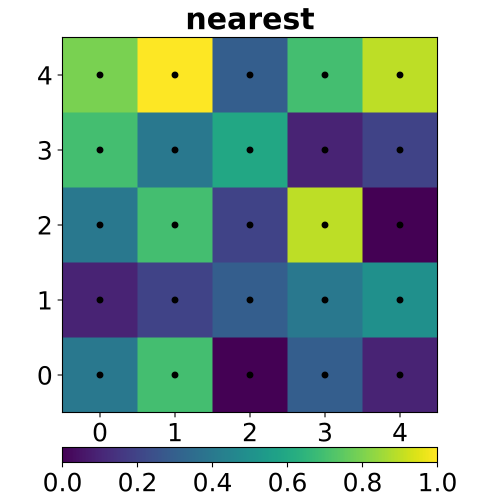{#fig-interpolation-2D-nearest-neighbor}

Este método de interpolación es computacionalmente poco costoso, no tiene que realizar promedios entre píxeles cercanos, y especialmente útil cuando es importante conservar los valores orginales de los píxeles, por ejemplo si vamos a aplicar máscaras de segmentación es pasos posteriores.


### Transformar la región de interés (ROI)

Para transformar la **región de interés (ROI)** hasta la posición objetivo, primero es necesario determinar las coordenadas de sus vértices en la imagen original.

Como se muestra en @fig-exercise-2-2-2-1, estas coordenadas pueden calcularse a partir de las dimensiones de la región, su orientación y las proyecciones de sus lados sobre los ejes de coordenadas.

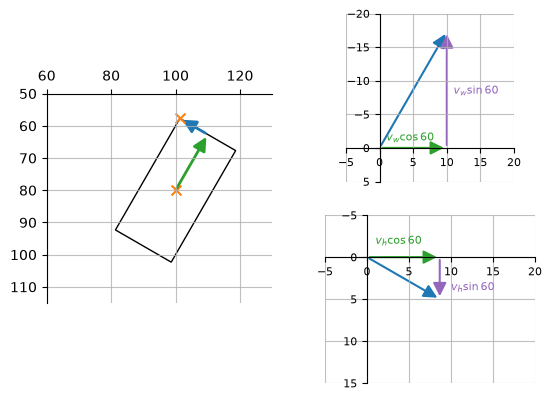

In [62]:
#| echo: false
#| label: fig-exercise-2-2-2-1
#| fig-cap: "Determinación de las coordenadas de los vértices de la región de interes"

# Parámetros iniciales
h, w = 20, 40
degrees = 60
O =  np.array([100, 80])
c_h, c_w = O

# Cálcula de la posición incial de la imagen
# Vector del centro de masas al punto intermedio entre A y B
v_w = [w/2 *  np.cos(np.deg2rad(degrees)), -w/2 * np.sin(np.deg2rad(degrees))]

# Vector del centro de masas al punto intermedio D y B
v_h = [h/2 * np.sin(np.deg2rad(degrees)), h/2 * np.cos(np.deg2rad(degrees))]

# Vértices
A = O + v_w - v_h
B = O + v_w + v_h
C = O - v_w - v_h
D = O - v_w + v_h
ROI = np.array([A, B, D, C])

fig, axes = plt.subplot_mosaic([['a', 'b'], ['a', 'c']])

def plot_vector_proyections(ax, vector, *, xlim=None, ylim=None):
    origin = [0, 0]
    vx, vy = vector

    plot_arrow(ax, origin, vector, lw=1.5, color='tab:blue')
    plot_arrow(ax, origin, [vx, 0], lw=1.5, color='tab:green')
    plot_arrow(ax, [vx, 0], vector, lw=1.5, color='tab:purple')

    ax.grid(True, alpha=.8)

    if xlim:
        ax.set_xlim(xlim)
    if ylim:
        ax.set_ylim(ylim)

    ax.set_aspect('equal')

    ax.spines[['top', 'right']].set_visible(False)
    ax.spines['bottom'].set_position(('data', 0))
    ax.spines['left'].set_position(('data', 0))

    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.tick_params(labelsize=8)

    ax.invert_yaxis()


plot_vector_proyections(axes['b'], v_w, xlim=(-5, 20), ylim=(-20, 5))
axes['b'].text(1, -1, r'$v_w\cos{60}$', fontsize=8, color='tab:green')
axes['b'].text(11, -8, r'$v_w\sin{60}$', fontsize=8, color='tab:purple')

plot_vector_proyections(axes['c'], v_h, xlim=(-5, 20), ylim=(-5, 15))
axes['c'].text(1, -1.5, r'$v_h\cos{60}$', fontsize=8, color='tab:green')
axes['c'].text(10, 4, r'$v_h\sin{60}$', fontsize=8, color='tab:purple')

axes['a'].scatter(*O, marker='x', s=50, color='tab:orange')
axes['a'].add_patch(Polygon(ROI, closed=True, fill=False))
plot_arrow(axes['a'], O, O + v_w, color='tab:green')
plot_arrow(axes['a'], O + v_w, O + v_w -v_h, color='tab:blue')
axes['a'].scatter(*A, marker='x', s=50, color='tab:orange')

axes['a'].spines[['bottom', 'right']].set_visible(False)
axes['a'].xaxis.tick_top()

axes['a'].grid(True, alpha=.8)
axes['a'].set_aspect('equal')

axes['a'].set_xlim(60, 130)
axes['a'].set_ylim(50, 115)

axes['a'].invert_yaxis()

Tras determinar las coordenadas de los vertices de la región de interés, se propone una  secuencia de transformaciones geométricas para situarla en la posición objetivo.

Como se ilustra en @fig-exercise-2-2-2-2, el procedimiento consta de tres operaciones: primero se aplica una rotación de 30º en sentido antihorario para alinear la región con los ejes de coordenadas, luego se realiza una traslación para situar el vertice superior izquierdo en el origen y finalmente se aplica un escalado uniforme para reducir sus dimensiones a la mitad.

```{mermaid}
%%| fig-width: 6
---
title: Secuencia de transformaciones geométricas
---
flowchart LR
    T1["Rotación de 30°"]
    T2["Traslación al origen"]
    T3["Escalado uniforme (0,5)"]

    T1 --> T2 --> T3
```

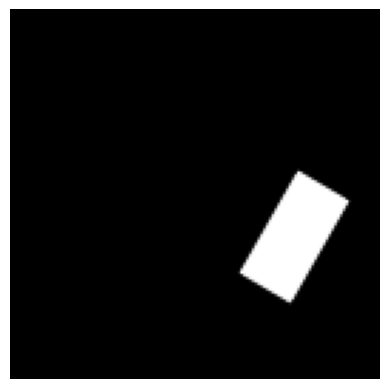

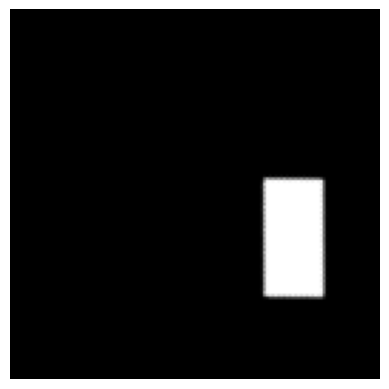

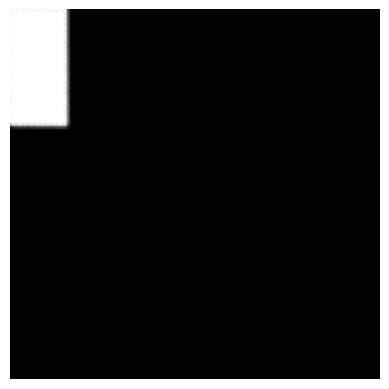

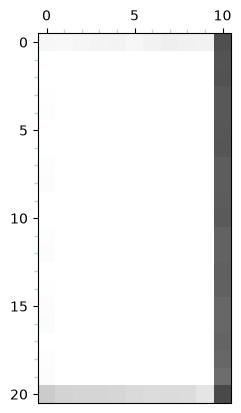

In [63]:
#| echo: false
#| label: fig-exercise-2-2-2-2
#| fig-cap: "Secuencia de transformaciones para recolocar la región de interés"
#| fig-subcap:
#|  - "Posición original del ROI"
#|  - "Rotación"
#|  - "Traslación del vertice superior al origen de coordenadas"
#|  - "Escalado de la imagen"
#| layout-ncol: 4
#| layout-valign: center
IMG_SHAPE = (130, 130)

img = np.zeros((*IMG_SHAPE, 3), dtype=np.uint8)
img = cv.fillPoly(img, [ROI.astype(np.int32)], (255, 255, 255), cv.LINE_AA)


# Transformaciones
T1 = cv.getRotationMatrix2D((100, 80), 30, 1)
# Calculo del vértice tras la rotación, que hay que trasladar al origen de coordeandas
A_rot = (T1 @ np.vstack((A[:, np.newaxis], 1))).flatten()
T2 = mtm.TRANSLATE(t_x=-A_rot[0], t_y=-A_rot[1])
T3 = mtm.SCALE(f_x=.5, f_y=.5)

img_1 = cv.warpAffine(img, T1[:2, :], IMG_SHAPE)
img_2 = cv.warpAffine(img_1, T2[:2, :], IMG_SHAPE)
img_3 = cv.warpAffine(img_2, T3[:2, :], (11, 21))


plot_image(img)
plot_image(img_1)
plot_image(img_2)
ax = plot_image(img_3, axis=True)
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(1))
ax.tick_params(
    axis="both",
    which="minor",
    length=3,
    width=1,
    color="lightblue"
)

plt.show()

## Ejercicio 2.3

### Deformación de una imagen

La deformación de la imagen se realiza mediante una transformación lineal por tramos, en la que se aplica un factor de escala horizontal diferente a cada mitad de la imagen, tal como se define en @eq-transformacion-tramos.

$$
\begin{aligned}
x' &=
\begin{cases}
\frac{2}{3}x, & x \leq W/2 \\[6pt]
\frac{W}{3} + \frac{4}{3}(x-W/2), & x > W/2
\end{cases}
\\[12pt]
y' &= y
\end{aligned}
$${#eq-transformacion-tramos}

Como se observa en @fig-exercise-2-3-1, la transformación modifica únicamente las coordenadas horizontales, manteniendo las verticales sin cambios:

- Mitad izquierda: se aplica un factor de escala de $2/3$, comprimiendo su anchura original de $W/2$ a $W/3$.
- Mitad derecha: se aplica un factor de escala de $4/3$, expandiendo su anchura original de $W/2$ a $2W/3$.

Finalmente, ambas regiones se combinan para obtener la imagen transformada, conservando la anchura total original $W$ y manteniendo la continuidad en el punto de unión entre las dos mitades.

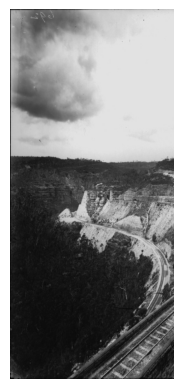

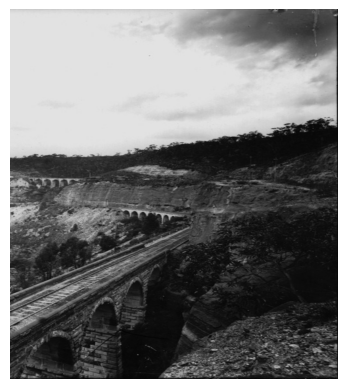

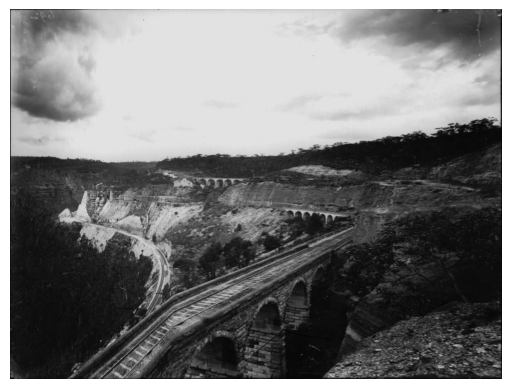

In [64]:
#| echo: false
#| label: fig-exercise-2-3-1
#| fig-cap: "Deformación horizontal mediante una transformación lineal por tramos"
#| fig-subcap:
#|   - "Mitad izquierda: escala 2/3"
#|   - "Mitad derecha: escala 4/3"
#|   - "Imagen resultante"
#| layout: [[1, 1], [0.7]]
#| layout-valign: center
img = cv.imread(DATA_DIR / 'zigzag.jpg', cv.IMREAD_COLOR_RGB)
h, w = img.shape[:2]
half = w // 2

# Ancho de destino
w_left =  w // 3
w_right = w - w_left

SCALE_LEFT = mtm.SCALE(f_x=w_left/half, f_y=1)
SCALE_RIGHT = (
    mtm.TRANSLATE(t_x=w_left, t_y=0) @
    mtm.SCALE(f_x=w_right/half, f_y=1) @
    mtm.TRANSLATE(t_x=-half, t_y=0))

img_left_global = cv.warpAffine(img, SCALE_LEFT[:2, :], (w, h))
img_right_global = cv.warpAffine(img, SCALE_RIGHT[:2, :], (w, h))

img_left_resize = img_left_global[:, :w_left]
img_right_resize = img_right_global[:, w_left:]

plot_image(img_left_resize)
plot_image(img_right_resize)

plot_image(np.hstack([img_left_resize, img_right_resize]))

plt.show()

### Transformación no lineal

In [65]:
#| include: false
x = np.linspace(0, 1, 10)
y = np.linspace(0, 1, 10)

# Transformación
xt = 2 * x
yt = y + 0.4 * (x - 0.5) ** 2 - 0.1

fig, (ax1, ax2) = plt.subplots(2, 1)

for i in np.linspace(0, 1, 9):
    ax1.plot(x, np.full_like(x, i), "b")
    ax2.plot(2 * x, i + 0.4 * (x - 0.5) ** 2 - 0.1, "r")

for i in np.linspace(0, 1, 9):
    ax1.plot(np.full_like(y, i), y, "b")
    ax2.plot(np.full_like(y, 2 * i), y + 0.4 * (i - 0.5) ** 2 - 0.1, "r")

ax1.set_title("Original")
ax2.set_title("Transformado")

for ax in (ax1, ax2):
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.grid(True)

ax1.axis('off')
ax2.axis('off')

fig.savefig(
    ASSETS_DIR / 'transformacion-no-lineal.png'
)
plt.close(fig)


::: {.columns layout-valign="center"}

::: {.column width="55%"}

Se considera la siguiente transformación geométrica:

$$
\begin{aligned}
y' &= y + 0.4(x - 0.5)^2 - 0.1 \\
x' &= 2x
\end{aligned}
$$ {#eq-transformacion-no-lineal}

La transformación @eq-transformacion-no-lineal es **no-lineal**, debido a la dependecia cuadrada de la coordenada $x$, a diferencia de las trasnformaciones afines esta transformación no conserva las líneas rectas, como se observa en la figura @fig-transformacion-no-lineal.

:::

::: {.column width="45%"}

![Transformación no lineal](assets/transformacion-no-lineal.png){#fig-transformacion-no-lineal width="100%"}

:::

:::

Aplicamos la tranformación @eq-transformacion-no-lineal a la imagen siguiendo la secuencia:

```{mermaid}
%%| fig-width: 6
---
title: Secuencia de transformaciones no lineales
---
flowchart LR
    T1["Marco con los píxeles de destino"]
    T2["(x',y')"]
    T3["(x,y)"]
    T4["Píxeles de origen"]

    T1 -- "Normalizar" --> T2
    T2 -- "Transformación inversa" --> T3
    T3 -- "Desnormalizar" --> T4
```

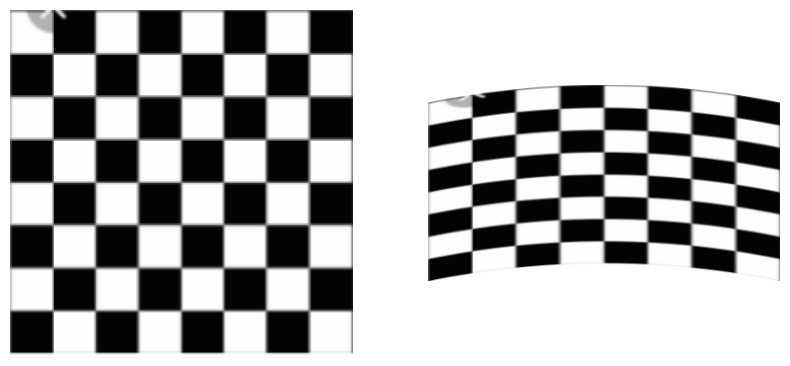

In [66]:
#| echo: false
#| label: fig-exercise-2-3-2
#| fig-cap: "Transformación no lineal del tablero de ajedrez"

img = cv.imread(DATA_DIR / "tableroAjedrez.png", cv.IMREAD_COLOR_RGB)
h, w = img.shape[:2]

# Dimensiones del marco de salida
h_out = int(np.ceil(1.1 * h))
w_out = 2 * w

# Malla con los píxeles de la imagen de salida
x_out, y_out = np.meshgrid(np.arange(w_out, dtype=np.float32), np.arange(h_out, dtype=np.float32))

# Normalizamos las coordenadas
x_out_norm = x_out * 2 / (w_out - 1)
y_out_norm = y_out * 1.1 / (h_out - 1) - 0.1

# Aplicamos la transformación inversa, que pixel de la imagen original le corresponde a cada pixel de salida
x_norm = x_out_norm / 2
y_norm = y_out_norm + 0.1 - 0.4 * (x_norm - 0.5)**2

map_x = (x_norm * (w-1)).astype(np.float32)
map_y = (y_norm * (w-1)).astype(np.float32)

img_tf = cv.remap(img,
    map_x,
    map_y,
    interpolation=cv.INTER_LINEAR,
    borderValue=(255, 255, 255)
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

plot_image(img, ax=ax1)
plot_image(img_tf, ax=ax2)

plt.show()